In [3]:
# Create a cleaned copy of the dataset
df_clean = df.copy()

# Fill missing numerical values with the median
for col in df_clean.select_dtypes(include="number").columns:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

# Fill missing categorical values with the mode
for col in df_clean.select_dtypes(
    include=["object", "category"]
).columns:
    if df_clean[col].isnull().any() and not df_clean[col].mode().empty:
        df_clean[col] = df_clean[col].fillna(
            df_clean[col].mode()[0]
        )

# Remove rows with missing pickup timestamps or fares
df_clean = df_clean.dropna(subset=["pickup", "fare"])

# Check the result
print("Dataset cleaned successfully!")
print(df_clean.head())




NameError: name 'df' is not defined

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the taxis dataset
df = sns.load_dataset("taxis")

# Display the dataset
print("Dataset loaded successfully!")
print(df.head())



Dataset loaded successfully!
               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1

In [5]:
# Create a copy of the dataset
df_clean = df.copy()

# Fill missing numerical values using the median
for col in df_clean.select_dtypes(include="number").columns:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

# Fill missing categorical values using the mode
for col in df_clean.select_dtypes(
    include=["object", "category"]
).columns:
    if df_clean[col].isnull().any() and not df_clean[col].mode().empty:
        df_clean[col] = df_clean[col].fillna(
            df_clean[col].mode()[0]
        )

# Remove rows with missing pickup and fare
df_clean = df_clean.dropna(subset=["pickup", "fare"])

print("Dataset cleaned successfully!")
print(df_clean.head())

Dataset cleaned successfully!
               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  


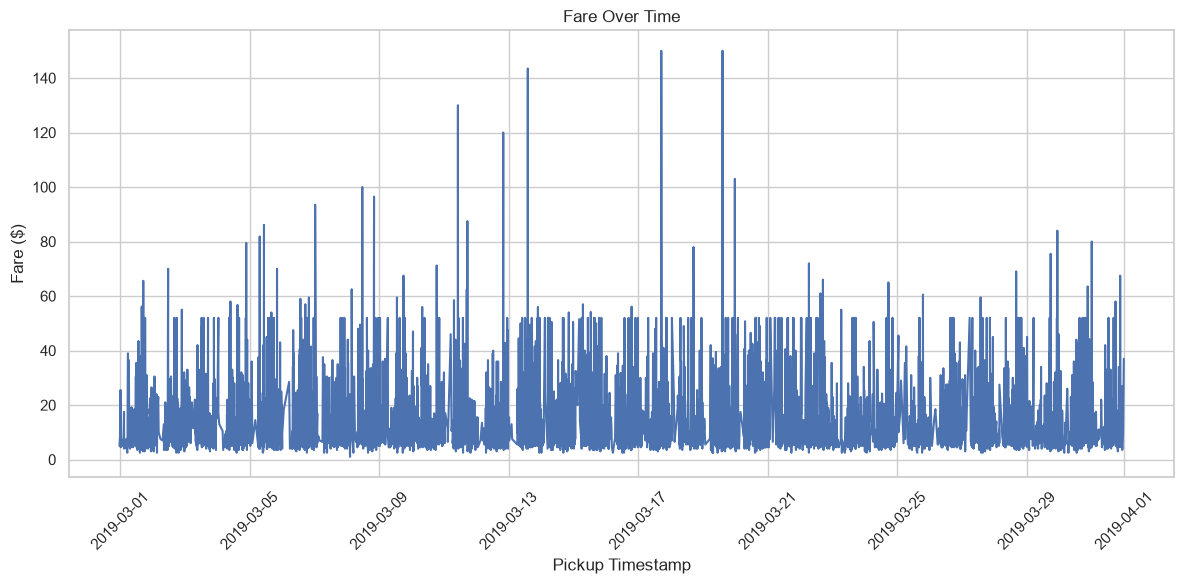

In [6]:
df_clean["pickup"] = pd.to_datetime(df_clean["pickup"])

df_line = df_clean.sort_values("pickup")

plt.figure(figsize=(12, 6))
plt.plot(df_line["pickup"], df_line["fare"])

plt.title("Fare Over Time")
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare ($)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()